In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# ------------------------
# Shared parameters
# ------------------------
year_start = 2024
year_end = 2100
num_points = 400

years = np.linspace(year_start, year_end, num_points)
t = years - year_start   # "years since launch" — used internally by the formulas below
span = year_end - year_start  # 76 years, used to rescale rate parameters

In [ ]:
# ------------------------
# Curve 1: Standard logistic
# ------------------------
L = 100          # max adoption (%)
k = 0.15                 # growth rate
t0 = span * 0.65         # inflection point (offset from year_start) — ~2074
y_logistic = L / (1 + np.exp(-k * (t - t0)))
 
# ------------------------
# Curve 2: Generalized logistic (A/B/M/G form)
# ------------------------
A = 0            # adoption % in 2025 (starting level)
B = 100           # adoption % in 2100 (ending level)
M = 2074         # inflection year (fastest growth)
G = 0.15         # growth rate
 
y_general = A + (B - A) / (1 + np.exp(-G * (years - M)))

 

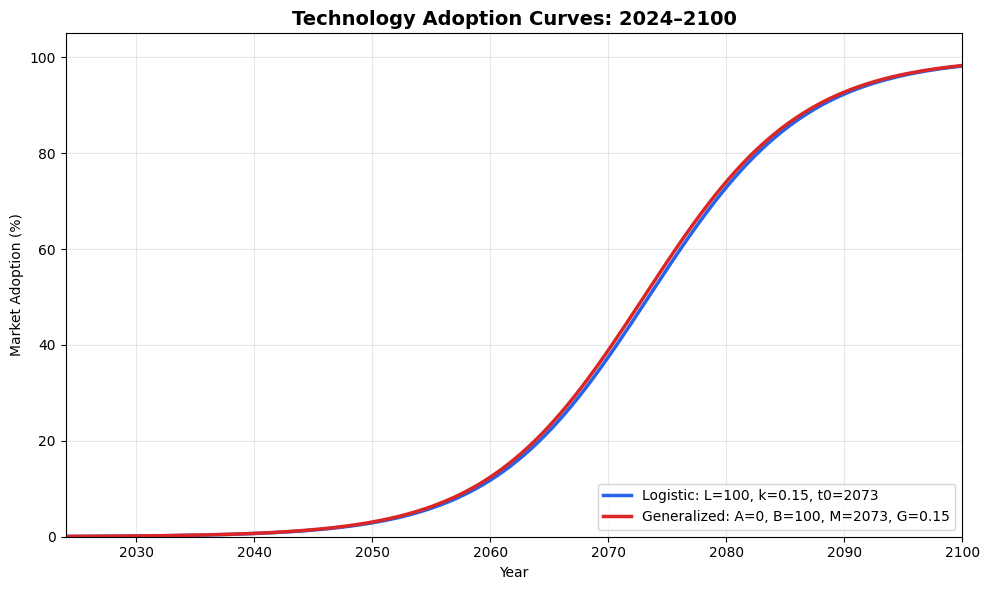

In [49]:

# ------------------------
# Plot all three
# ------------------------
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(years, y_logistic, linewidth=2.5, color="#2563eb",
         label=f"Logistic: L={L}, k={k}, t0={year_start + t0:.0f}")
ax.plot(years, y_general, linewidth=2.5, color="#dc2626",
         label=f"Generalized: A={A}, B={B}, M={M}, G={G}")

 
ax.set_title("Technology Adoption Curves: 2024–2100", fontsize=14, fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Market Adoption (%)")
ax.set_ylim(0, max(L * 1.05, 10))
ax.set_xlim(year_start, year_end)
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
 
plt.tight_layout()
 
 